In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import yaml
import seaborn as sns
from utils.plots import *
from utils.figures import cmap

FIG = 'fig_trends'
config_fpath = Path(f'{FIG}.yml')
df_fpath = Path(f'{FIG}_df.csv')


In [3]:
default = {'duration': 11, 'sample_freq':64, 'snr':10}

df = pd.read_csv(df_fpath)
for fig in ['fig1', 'fig2', 'fig3']:
    df_fig = pd.read_csv(f'../{fig}/{fig}_df.csv')
    df = pd.concat([df, df_fig])
df = df.drop_duplicates()


In [4]:
def capim(x_var, y_var, methods, method_names, hues,
               x_label='', y_label='', legend=False,
               x_tick_labels=True, y_ticks=None, y_tick_labels=None,
               log=False, dodge=0.15):
    df_temp = df.query(' & '.join([f'{var}=={val}' for var, val in default.items() if var != x_var])).copy()
    df_temp = df_temp[df_temp.method.isin(methods)]
    df_temp = df_temp.dropna(subset=[x_var, y_var])
    df_temp['meth'] = df_temp.method.apply(lambda x: method_names[methods.index(x)])
    if log:
        df_temp[y_var] = np.log10(df_temp[y_var])
    sns.pointplot(df_temp, x=x_var, y=y_var,
                    hue='meth', palette=hues, hue_order=method_names,
                    estimator='median', errorbar=('pi', 90),
                    dodge=dodge, 
                    linewidth=1.5,
                    )
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.yticks(y_ticks, y_tick_labels)
    xticks = sorted(df_temp[x_var].unique())
    if x_tick_labels:
        xticklabs = [f'{x:0g}' for x in xticks]
    else:
        xticklabs = []
    plt.xticks(range(len(xticks)), xticklabs)
    if legend:
        plt.legend(frameon=False, borderpad=0, borderaxespad=1,
                   loc='center left', bbox_to_anchor=(1, 0.5))
    else:
        plt.gca().get_legend().remove()
    sns.despine(trim=True)


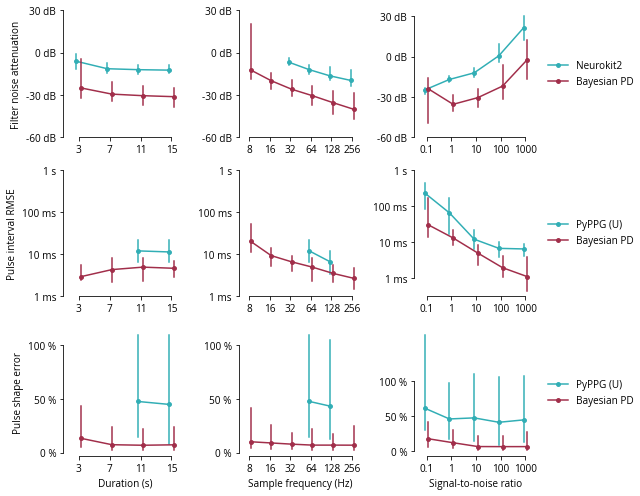

In [5]:
with open(config_fpath, 'r') as f:
    config = yaml.safe_load(f)
    
x_list = [
    ('duration', 'Duration (s)'),
    ('sample_freq', 'Sample frequency (Hz)'),
    ('snr', 'Signal-to-noise ratio'),
]

plt.figure(figsize=(9,7))
for i, y in enumerate(config['y']):
    y_var = y['metric']
    y_label = y['name']
    y_ticks = y.get('ticks')
    y_tick_labels = y.get('labels')
    log = y.get('log', False)
    for j, (x_var, x_label) in enumerate(x_list):
        methods = [x['method'] for x in y['x']]
        method_names = [x['name'] for x in y['x']] 
        hues = [cmap(mn) for mn in method_names]
        plt.subplot(3,3,i*3+j+1)
        capim(x_var, y_var, methods, method_names, hues,
                   x_label if i==2 else '',
                   y_label if j==0 else '',
                   legend = j==2,
                   y_ticks = y_ticks,
                   y_tick_labels = y_tick_labels,
                   log = log,
                   dodge = 0.15,
                   )
plt.savefig(f'{FIG}.pdf', transparent=True)
plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
plt.show()